# Monitoring sites — enquête géographique pas à pas


# 0. Bibliothèques


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics.pairwise import haversine_distances
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist
from sklearn.manifold import TSNE
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from itertools import combinations
from collections import Counter
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, 'Ouvrir le notebook depuis le dépôt.'
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .2})

# 1. Charger les données


In [2]:
raw = pd.read_csv(ROOT / 'data/ecology/monitoring_sites.csv')
df = pd.read_csv(ROOT / 'data/ecology/cleaned/monitoring_sites_cleaned.csv')
print('Brut :', raw.shape, '| Nettoyé :', df.shape)
display(df.head(5))

Brut : (64, 14) | Nettoyé : (64, 14)


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active


### 1.1 Identifier les colonnes et leurs types


In [3]:
display(pd.DataFrame({'type': df.dtypes.astype(str),
                      'valeurs_manquantes': df.isna().sum(),
                      'modalites_distinctes': df.nunique(dropna=True)}))

,type,valeurs_manquantes,modalites_distinctes
site_code,object,0,64
site_name,object,0,64
site_category,object,0,3
region,object,0,3
jurisdiction,object,0,3
latitude,float64,0,64
longitude,float64,0,64
elevation_m,float64,1,57
habitat_category,object,0,8
cave_access_category,object,0,2


### 1.2 Vérifier les doublons


In [4]:
print('Doublons exacts dans la source brute :', raw.duplicated().sum())
print('Doublons de site_code dans la source brute :', raw.duplicated('site_code').sum())
print('Doublons exacts après nettoyage :', df.duplicated().sum())
print('Doublons de site_code après nettoyage :', df.duplicated('site_code').sum())
assert df.site_code.is_unique and df.site_code.notna().all()

Doublons exacts dans la source brute : 0
Doublons de site_code dans la source brute : 0
Doublons exacts après nettoyage : 0
Doublons de site_code après nettoyage : 0


### 1.3 Examiner les valeurs manquantes


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename('nombre_manquants').to_frame())
display(df.loc[df.elevation_m.isna(), ['site_code', 'region', 'elevation_m']])

,nombre_manquants
programme_end_date,64
elevation_m,1


,site_code,region,elevation_m
8,KNT-CYP,Kintara Karst Cluster,NaN


**Interprétation :** il manque une altitude (`KNT-CYP`) et les dates de fin du programme ne sont pas renseignées.


# 2. Contrôles géographiques


In [6]:
for col in ['latitude', 'longitude', 'elevation_m']:
    df[col] = pd.to_numeric(df[col], errors='raise')
df['coord_valides'] = df.latitude.between(-90, 90) & df.longitude.between(-180, 180)
df['coord_dupliquees'] = df.duplicated(['latitude', 'longitude'], keep=False)
print('Coordonnées absentes ou hors limites :', (~df.coord_valides).sum())
print('Sites avec coordonnées strictement identiques :', df.coord_dupliquees.sum())
display(df.loc[~df.coord_valides | df.coord_dupliquees, ['site_code','latitude','longitude']])

Coordonnées absentes ou hors limites : 0
Sites avec coordonnées strictement identiques : 0


,site_code,latitude,longitude


### 2.1 Vérifier la chronologie des programmes


In [7]:
start = pd.to_datetime(df.programme_start_date, errors='raise')
end = pd.to_datetime(df.programme_end_date, errors='raise')
print('Dates de fin antérieures au début :', (end < start).sum())
print('Dates de fin non renseignées :', end.isna().sum())

Dates de fin antérieures au début : 0
Dates de fin non renseignées : 64


**Bilan provisoire :** aucun site n’est supprimé.


# 3. Explorer les sites


In [8]:
display(df.region.value_counts().rename('nombre_sites').to_frame())
display(pd.crosstab(df.region, df.site_category))

,nombre_sites
region,
Kintara Karst Cluster,22
Eastern Avelora Agricultural Cluster,22
Tembara Coastal Cluster,20


site_category,cave monitoring,habitat monitoring,orchard monitoring
region,,,
Eastern Avelora Agricultural Cluster,0,9,13
Kintara Karst Cluster,7,15,0
Tembara Coastal Cluster,1,16,3


### 3.1 Visualiser les catégories de suivi


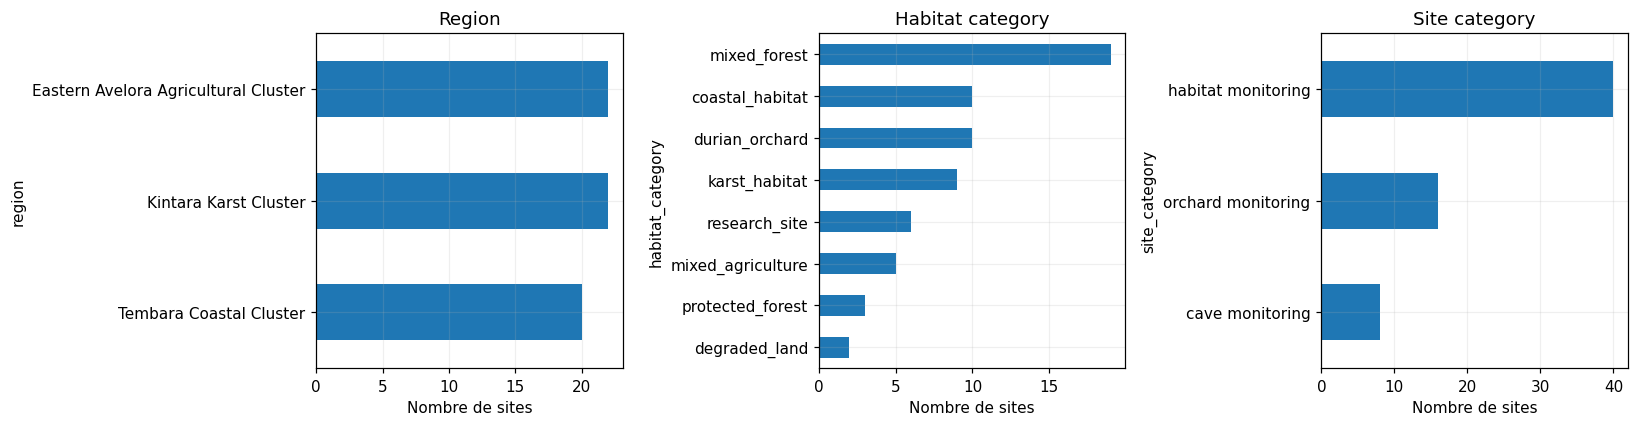

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['region', 'habitat_category', 'site_category']):
    df[col].value_counts().sort_values().plot.barh(ax=ax)
    ax.set_title(col.replace('_',' ').capitalize()); ax.set_xlabel('Nombre de sites')
plt.tight_layout(); plt.show()

**Lecture :** ces effectifs décrivent un échantillonnage choisi, pas la proportion réelle d’habitats dans un territoire fictif.


### 3.2 Carte exploratoire des sites


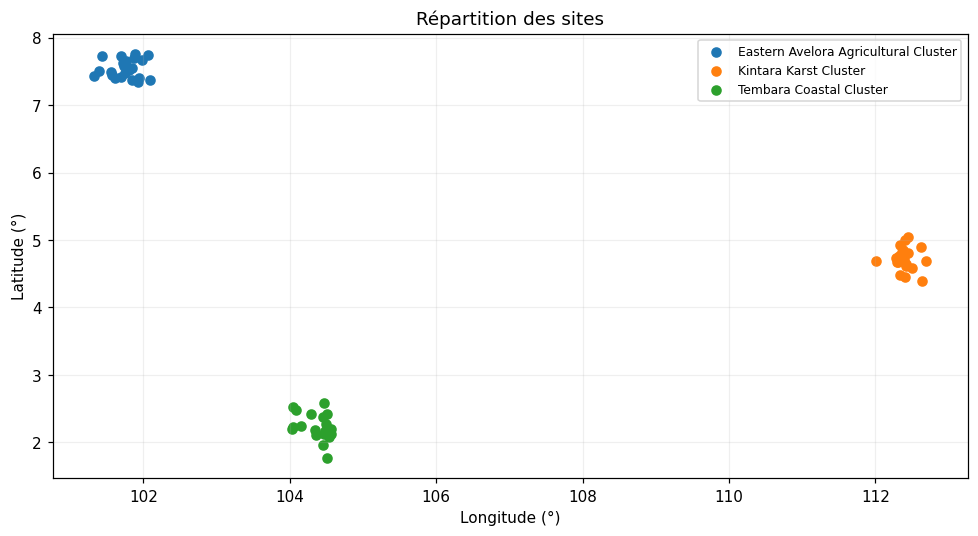

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for region, group in df.groupby('region'):
    ax.scatter(group.longitude, group.latitude, label=region, s=35)
ax.set(xlabel='Longitude (°)', ylabel='Latitude (°)', title='Répartition des sites')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# 4. Distances entre sites


In [11]:
EARTH_KM = 6371.0088
valid = df.loc[df.coord_valides].copy()
centres = valid.groupby('region')[['latitude','longitude']].median()
display(centres)

,latitude,longitude
region,,
Eastern Avelora Agricultural Cluster,7.51305,101.75595
Kintara Karst Cluster,4.72750,112.38235
Tembara Coastal Cluster,2.19175,104.45575


### 4.1 Distance au centre régional


In [12]:
df['distance_centre_km'] = np.nan
for region, group in valid.groupby('region'):
    coords = np.radians(group[['latitude','longitude']].to_numpy())
    centre = np.radians(centres.loc[[region]].to_numpy())
    df.loc[group.index,'distance_centre_km'] = (
        haversine_distances(coords, centre)[:,0] * EARTH_KM)
display(df.groupby('region').distance_centre_km.describe().round(2))

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
Eastern Avelora Agricultural Cluster,22.0,23.89,12.81,4.07,14.02,22.94,30.26,48.34
Kintara Karst Cluster,22.0,19.87,13.09,0.74,10.78,13.47,31.16,46.94
Tembara Coastal Cluster,20.0,26.60,17.20,3.54,12.53,22.76,44.55,59.18


### 4.2 Distance au site régional le plus proche


In [13]:
df['distance_voisin_km'] = np.nan
for region, group in valid.groupby('region'):
    coords = np.radians(group[['latitude','longitude']].to_numpy())
    distances = haversine_distances(coords) * EARTH_KM
    np.fill_diagonal(distances, np.inf)
    df.loc[group.index,'distance_voisin_km'] = distances.min(axis=1)
display(df.nlargest(10, 'distance_voisin_km')[['site_code','region','distance_voisin_km']].round(2))

,site_code,region,distance_voisin_km
9,KNT-YRX,Kintara Karst Cluster,30.41
15,KNT-CHP,Kintara Karst Cluster,25.77
29,AVL-ARU,Eastern Avelora Agricultural Cluster,24.77
24,KNT-TEX,Kintara Karst Cluster,23.17
53,TMB-UVF,Tembara Coastal Cluster,23.13
20,KNT-QWU,Kintara Karst Cluster,22.34
63,TMB-DLQ,Tembara Coastal Cluster,19.81
62,TMB-QCB,Tembara Coastal Cluster,18.96
30,AVL-GRB,Eastern Avelora Agricultural Cluster,17.58
48,TMB-CKU,Tembara Coastal Cluster,16.48


### 4.3 Vérifier les régions déclarées


In [14]:
dist_centres = haversine_distances(
    np.radians(valid[['latitude','longitude']].to_numpy()),
    np.radians(centres.to_numpy())) * EARTH_KM
df['region_plus_proche'] = pd.NA
df.loc[valid.index, 'region_plus_proche'] = centres.index[dist_centres.argmin(axis=1)]
print('Régions différentes du centre le plus proche :',
      df.loc[valid.index,'region_plus_proche'].ne(df.loc[valid.index,'region']).sum())

Régions différentes du centre le plus proche : 0


### 4.4 Visualiser les distances


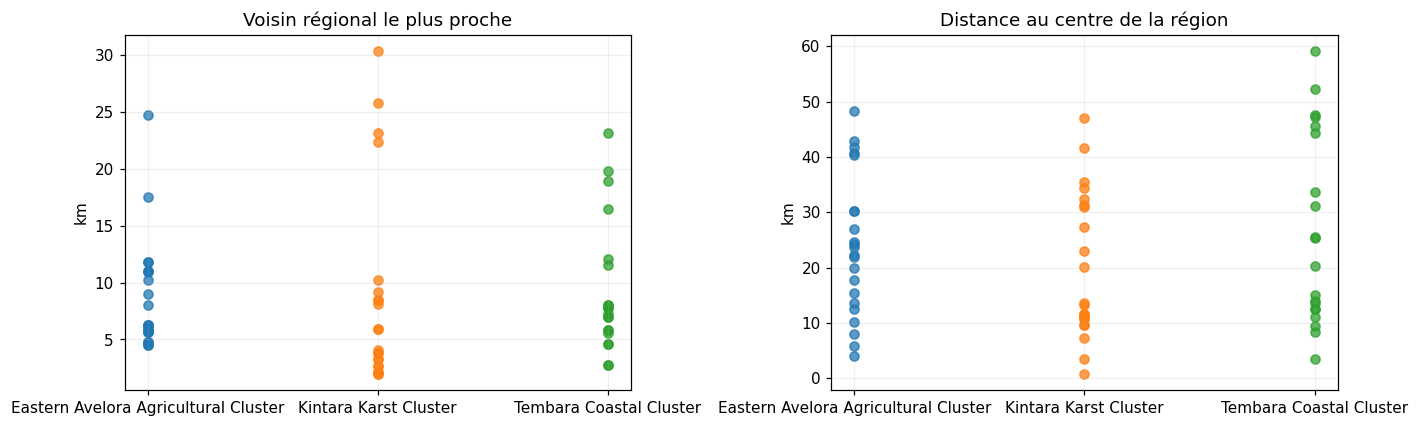

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for region, g in df.groupby('region'):
    axes[0].scatter([region]*len(g), g.distance_voisin_km, alpha=.75)
    axes[1].scatter([region]*len(g), g.distance_centre_km, alpha=.75)
axes[0].set(ylabel='km', title='Voisin régional le plus proche')
axes[1].set(ylabel='km', title='Distance au centre de la région')
plt.tight_layout();plt.show()

# 5. Bloc 2 : Clustering


### a. Variables numériques et catégories


In [16]:
profil_sites=df[['site_code','region','site_category','habitat_category',
                 'distance_voisin_km','distance_centre_km','elevation_m']].copy()
for col in ['distance_voisin_km','distance_centre_km','elevation_m']:
    serie=profil_sites.groupby('region')[col]
    ecart=serie.transform('std').replace(0,np.nan)
    profil_sites[col]=(profil_sites[col]-serie.transform('mean'))/ecart
    profil_sites[col]=profil_sites[col].fillna(0)
X_site_cat=pd.get_dummies(profil_sites[['site_category','habitat_category']],dtype=int)
X_site_num=profil_sites[['distance_voisin_km','distance_centre_km','elevation_m']]
X_site_cluster=StandardScaler().fit_transform(pd.concat([X_site_num,X_site_cat],axis=1))
print('Sites :',len(profil_sites),'| Variables encodées :',X_site_cluster.shape[1])

Sites : 64 | Variables encodées : 14


### b. K-Means : choisir k avec silhouette


In [17]:
distances_sites=cdist(X_site_cluster,X_site_cluster)
scores_sites=[]
for k in [2,3,4,5]:
    km=KMeans(n_clusters=k,n_init=20,random_state=42).fit(X_site_cluster)
    scores_sites.append({'k':k,'silhouette':silhouette_score(distances_sites,km.labels_,metric="precomputed"),
                         'minimum_groupe':int(np.bincount(km.labels_).min())})
scores_sites=pd.DataFrame(scores_sites)
display(scores_sites.round(3))

,k,silhouette,minimum_groupe
0,2,0.246,24
1,3,0.326,8
2,4,0.320,7
3,5,0.363,6


In [18]:
valid_sites=scores_sites.loc[scores_sites.minimum_groupe>=3]
k_site=int(valid_sites.sort_values('silhouette',ascending=False).iloc[0].k)
modele_site=KMeans(n_clusters=k_site,n_init=20,random_state=42).fit(X_site_cluster)
profil_sites['cluster_KMeans']=modele_site.labels_
print('k choisi :',k_site)
display(profil_sites.cluster_KMeans.value_counts().sort_index())

k choisi : 5


cluster_KMeans
0    15
1    21
2     8
3    14
4     6

### c. Classification hiérarchique (Ward)


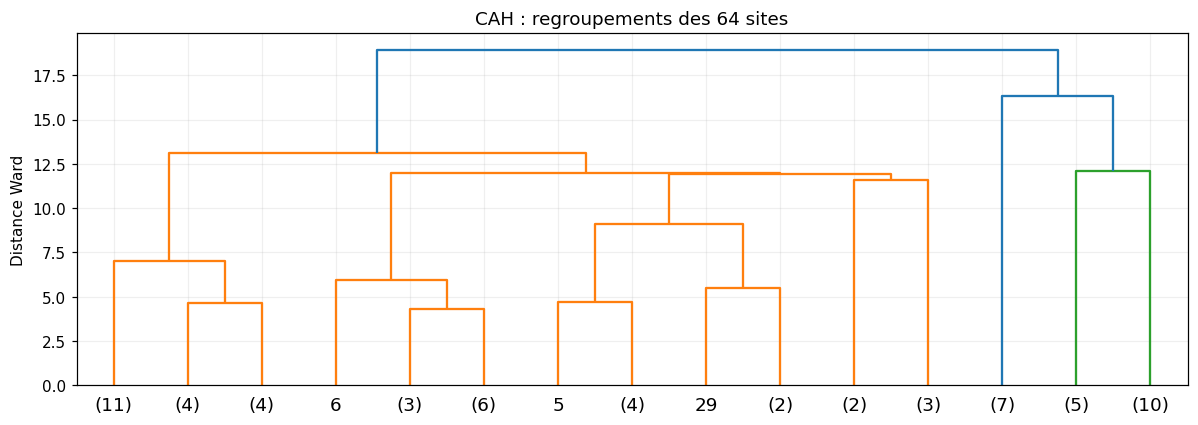

In [19]:
hierarchie_sites=linkage(X_site_cluster,method='ward')
fig,ax=plt.subplots(figsize=(11,4))
dendrogram(hierarchie_sites,truncate_mode='lastp',p=15,ax=ax)
ax.set(title='CAH : regroupements des 64 sites',ylabel='Distance Ward')
plt.tight_layout();plt.show()

### d. Comparer K-Means et CAH


In [20]:
cah_sites=AgglomerativeClustering(n_clusters=k_site,linkage='ward')
profil_sites['cluster_CAH']=cah_sites.fit_predict(X_site_cluster)
print('ARI K-Means / CAH :',round(adjusted_rand_score(
    profil_sites.cluster_KMeans,profil_sites.cluster_CAH),3))
display(pd.crosstab(profil_sites.cluster_KMeans,profil_sites.cluster_CAH))

ARI K-Means / CAH : 0.668


cluster_CAH,0,1,2,3,4
cluster_KMeans,,,,,
0,0,0,0,10,5
1,2,19,0,0,0
2,1,0,7,0,0
3,14,0,0,0,0
4,6,0,0,0,0


### e. Profils et projection ACP


,distance_voisin_km,distance_centre_km,elevation_m
cluster_KMeans,,,
0,-0.33,-0.22,-0.12
1,0.27,0.61,0.14
2,-0.37,-0.59,-0.11
3,-0.04,-0.29,-0.11
4,0.49,-0.12,0.23


site_category,cave monitoring,habitat monitoring,orchard monitoring
cluster_KMeans,,,
0,0,0,15
1,0,21,0
2,8,0,0
3,0,14,0
4,0,5,1


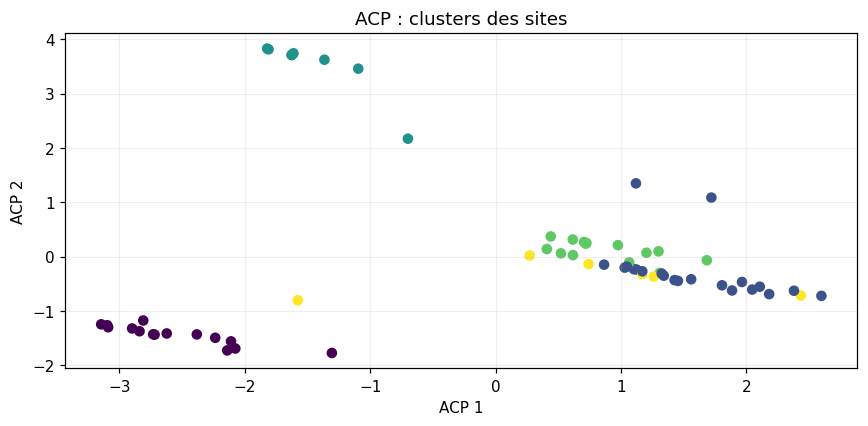

In [21]:
display(profil_sites.groupby('cluster_KMeans')[
    ['distance_voisin_km','distance_centre_km','elevation_m']].mean().round(2))
display(pd.crosstab(profil_sites.cluster_KMeans,profil_sites.site_category))
plan_sites=PCA(n_components=2).fit_transform(X_site_cluster)
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(plan_sites[:,0],plan_sites[:,1],c=profil_sites.cluster_KMeans,s=35)
ax.set(title='ACP : clusters des sites',xlabel='ACP 1',ylabel='ACP 2')
plt.tight_layout();plt.show()

**Interprétation des clusters :** les groupes suivent surtout les types de sites. Le cluster 0 regroupe 15 sites de vergers et le cluster 2 contient 8 sites de grottes. Les clusters 1 et 3 concernent des sites de suivi d’habitats (21 et 14 sites). Le dernier cluster est plus petit (6 sites, dont 5 de suivi d’habitats et 1 de verger). Les variables numériques ont été standardisées : leurs moyennes dans le tableau sont donc des scores, pas des distances en kilomètres. On obtient des **profils de sites**, pas des anomalies confirmées.


→ Lecture : groupes de profils de sites, pas anomalies confirmées.


# 6. ACP et t-SNE


### a. ACP sur les coordonnées et altitudes d’une région


In [22]:
region_test = df.region.value_counts().index[0]
subset = df.loc[df.region.eq(region_test)].dropna(subset=['elevation_m']).copy()
cols_acp = ['latitude', 'longitude', 'elevation_m']
X_region = StandardScaler().fit_transform(subset[cols_acp])
acp_region = PCA(n_components=2).fit(X_region)
points_acp = acp_region.transform(X_region)
print('Région :', region_test, '| Variance expliquée :', acp_region.explained_variance_ratio_.round(3))

Région : Kintara Karst Cluster | Variance expliquée : [0.41 0.32]


### b. Visualisation ACP


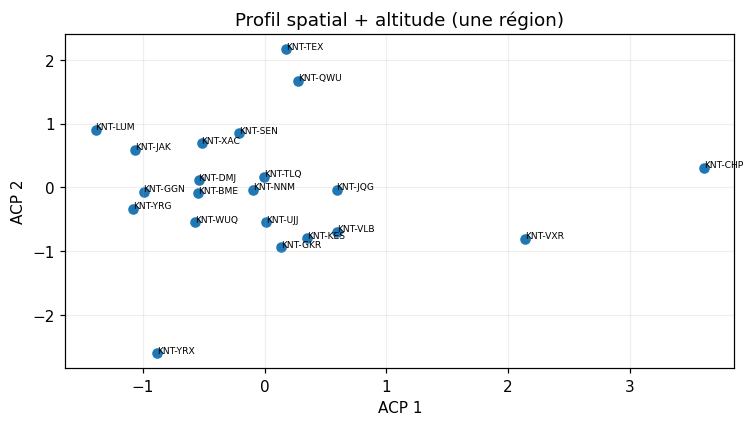

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(points_acp[:,0], points_acp[:,1], s=35)
for i,site in enumerate(subset.site_code):
    ax.annotate(site,(points_acp[i,0],points_acp[i,1]),fontsize=6)
ax.set(xlabel='ACP 1',ylabel='ACP 2',title='Profil spatial + altitude (une région)')
plt.tight_layout();plt.show()

### c. t-SNE (comparaison visuelle)


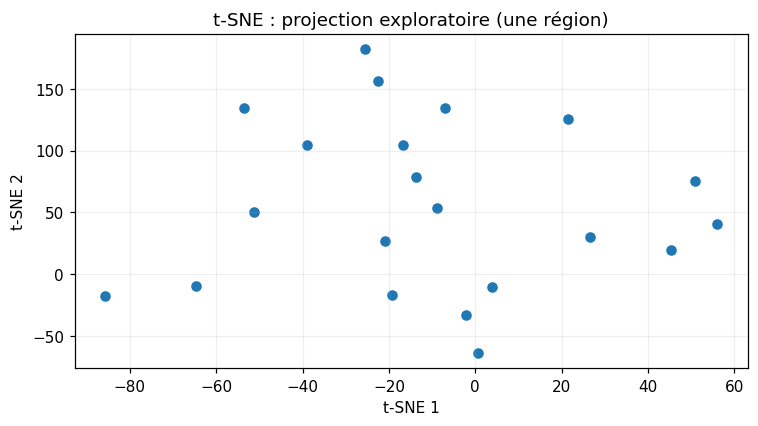

In [24]:
tsn_region = TSNE(n_components=2, perplexity=5, init='random',
                   learning_rate='auto', random_state=42).fit_transform(X_region)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(tsn_region[:,0],tsn_region[:,1],s=35)
ax.set(title='t-SNE : projection exploratoire (une région)',xlabel='t-SNE 1',ylabel='t-SNE 2')
plt.tight_layout();plt.show()

**Lecture :** 3 variables → 2 axes ; les distances t-SNE ne sont pas des kilomètres.


# 7. Bloc 3 : Détection univariée


**Pourquoi garder les valeurs atypiques ?** Un site éloigné des autres ou une altitude peu courante peut correspondre à un choix de suivi écologique. Comme les coordonnées sont valides et qu'aucun doublon n'a été trouvé, on préfère **signaler les cas à vérifier sans modifier les données**.


### IQR : comprendre le seuil avant de détecter


In [25]:
exemple = df.loc[df.region.eq(sorted(df.region.unique())[0]), 'distance_voisin_km'].dropna()
q1, q3 = exemple.quantile([.25,.75]); iqr = q3-q1
print(f'Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} km')
print(f'Bornes IQR = [{q1-1.5*iqr:.2f} ; {q3+1.5*iqr:.2f}] km')

Q1=5.65, Q3=11.01, IQR=5.36 km
Bornes IQR = [-2.38 ; 19.04] km


### Appliquer IQR à chaque région et variable


In [26]:
variables = ['distance_centre_km','distance_voisin_km','elevation_m']
rows_iqr=[]
for region, g in df.groupby('region'):
    for var in variables:
        vals=g[var].dropna(); q1,q3=vals.quantile([.25,.75]); spread=q3-q1
        usable=len(vals)>=8 and spread>1e-12
        lower,upper=q1-1.5*spread,q3+1.5*spread
        for _,r in g.iterrows():
            x=r[var];flag=bool(usable and pd.notna(x) and (x<lower or x>upper))
            rows_iqr.append(dict(observation=r.site_code,groupe=region,variable=var,
                methode='IQR',valeur=x,score=x,borne_basse=lower if usable else np.nan,
                borne_haute=upper if usable else np.nan, n_reference=len(vals),
                applicable=bool(usable and pd.notna(x)),signalee=flag,
                regle='hors bornes IQR 1,5',interpretation='À examiner dans la région'))
tests_iqr=pd.DataFrame(rows_iqr)
display(tests_iqr.loc[tests_iqr.signalee, ['observation','groupe','variable','valeur','borne_haute']].round(2))

,observation,groupe,variable,valeur,borne_haute
27,AVL-ARU,Eastern Avelora Agricultural Cluster,distance_voisin_km,24.77,19.04
92,KNT-YRX,Kintara Karst Cluster,distance_voisin_km,30.41,18.28
98,KNT-CHP,Kintara Karst Cluster,distance_voisin_km,25.77,18.28
103,KNT-QWU,Kintara Karst Cluster,distance_voisin_km,22.34,18.28
107,KNT-TEX,Kintara Karst Cluster,distance_voisin_km,23.17,18.28
120,KNT-CHP,Kintara Karst Cluster,elevation_m,418.80,417.20
161,TMB-UVF,Tembara Coastal Cluster,distance_voisin_km,23.13,20.62


**Lecture :** ces seuils distinguent des positions rares, pas des valeurs physiquement fausses.


### Z-score : écart à la moyenne


In [27]:
rows_z=[]
for region,g in df.groupby('region'):
    for var in variables:
        vals=g[var].dropna();mean=vals.mean();sd=vals.std(ddof=1)
        usable=len(vals)>=8 and pd.notna(sd) and sd>1e-12
        for _,r in g.iterrows():
            x=r[var];z=(x-mean)/sd if usable and pd.notna(x) else np.nan
            rows_z.append(dict(observation=r.site_code,groupe=region,variable=var,
                methode='Z-score',valeur=x,score=z,borne_basse=mean-3*sd if usable else np.nan,
                borne_haute=mean+3*sd if usable else np.nan,n_reference=len(vals),
                applicable=bool(usable and pd.notna(x)),signalee=bool(pd.notna(z) and abs(z)>3),
                regle='|z| > 3',interpretation='À examiner dans la région'))
tests_z=pd.DataFrame(rows_z)
display(tests_z.loc[tests_z.signalee,['observation','variable','score']].round(2))

,observation,variable,score
27,AVL-ARU,distance_voisin_km,3.28


### Z-score modifié : écart à la médiane


In [28]:
rows_mad=[]
for region,g in df.groupby('region'):
    for var in variables:
        vals=g[var].dropna();med=vals.median();mad=(vals-med).abs().median()
        usable=len(vals)>=8 and pd.notna(mad) and mad>1e-12
        for _,r in g.iterrows():
            x=r[var];z=.6745*(x-med)/mad if usable and pd.notna(x) else np.nan
            rows_mad.append(dict(observation=r.site_code,groupe=region,variable=var,
                methode='Z-modifie',valeur=x,score=z,
                borne_basse=med-3.5*mad/.6745 if usable else np.nan,
                borne_haute=med+3.5*mad/.6745 if usable else np.nan,n_reference=len(vals),
                applicable=bool(usable and pd.notna(x)),signalee=bool(pd.notna(z) and abs(z)>3.5),
                regle='|z_mod| > 3,5',interpretation='À examiner dans la région'))
tests_mad=pd.DataFrame(rows_mad)
display(tests_mad.loc[tests_mad.signalee,['observation','variable','score']].round(2))

,observation,variable,score
27,AVL-ARU,distance_voisin_km,7.06
28,AVL-GRB,distance_voisin_km,4.31
92,KNT-YRX,distance_voisin_km,5.78
98,KNT-CHP,distance_voisin_km,4.72
103,KNT-QWU,distance_voisin_km,3.94
107,KNT-TEX,distance_voisin_km,4.13
161,TMB-UVF,distance_voisin_km,4.32


### Comparer les trois méthodes


In [29]:
tests=pd.concat([tests_iqr,tests_z,tests_mad],ignore_index=True)
stat_flags=tests.loc[tests.signalee].copy()
stat_ids=stat_flags.observation.unique()
display(tests.groupby(['variable','methode']).signalee.sum().unstack(fill_value=0))
print('Sites distincts signalés par les méthodes statistiques :',len(stat_ids))
display(df.loc[df.site_code.isin(stat_ids),['site_code','region','distance_voisin_km','elevation_m']].round(2))

Sites distincts signalés par les méthodes statistiques : 7


methode,IQR,Z-modifie,Z-score
variable,,,
distance_centre_km,0,0,0
distance_voisin_km,6,7,1
elevation_m,1,0,0


,site_code,region,distance_voisin_km,elevation_m
9,KNT-YRX,Kintara Karst Cluster,30.41,192.3
15,KNT-CHP,Kintara Karst Cluster,25.77,418.8
20,KNT-QWU,Kintara Karst Cluster,22.34,232.5
24,KNT-TEX,Kintara Karst Cluster,23.17,82.6
29,AVL-ARU,Eastern Avelora Agricultural Cluster,24.77,314.3
30,AVL-GRB,Eastern Avelora Agricultural Cluster,17.58,186.4
53,TMB-UVF,Tembara Coastal Cluster,23.13,53.4


# 8. LOF


### Modèle principal : cinq voisins


In [30]:
lof_rows=[]
for region,g in df.loc[df.coord_valides].groupby('region'):
    model=LocalOutlierFactor(n_neighbors=5,metric='haversine',algorithm='ball_tree',
                             contamination='auto')
    model.fit_predict(np.radians(g[['latitude','longitude']]))
    for site,score in zip(g.site_code,-model.negative_outlier_factor_):
        lof_rows.append(dict(site_code=site,region=region,k=5,score=score,
                             signalee=bool(score>1.5)))
lof_main=pd.DataFrame(lof_rows)
display(lof_main.loc[lof_main.signalee].sort_values('score',ascending=False).round(3))

,site_code,region,k,score,signalee
26,KNT-YRX,Kintara Karst Cluster,5,3.729,True
53,TMB-UVF,Tembara Coastal Cluster,5,2.816,True
41,KNT-TEX,Kintara Karst Cluster,5,1.747,True
48,TMB-CKU,Tembara Coastal Cluster,5,1.535,True
32,KNT-CHP,Kintara Karst Cluster,5,1.519,True


### Sensibilité : trois et huit voisins


In [31]:
sens=[]
for region,g in df.loc[df.coord_valides].groupby('region'):
    for k in [3,8]:
        model=LocalOutlierFactor(n_neighbors=k,metric='haversine',algorithm='ball_tree',
                                 contamination='auto')
        model.fit_predict(np.radians(g[['latitude','longitude']]))
        for site,score in zip(g.site_code,-model.negative_outlier_factor_):
            sens.append(dict(site_code=site,k=k,score=score,signalee=bool(score>1.5)))
lof_sensitivity=pd.concat([lof_main[['site_code','k','score','signalee']],pd.DataFrame(sens)])
display(lof_sensitivity.groupby('k').signalee.sum().rename('sites_signales'))
display(lof_sensitivity.pivot(index='site_code',columns='k',values='score').loc[
    lof_sensitivity.groupby('site_code').signalee.any()].round(2))

k
3    8
5    5
8    6

k,3,5,8
site_code,,,
AVL-ARU,1.77,1.47,1.37
AVL-SEY,1.55,1.23,1.39
KNT-CHP,1.73,1.52,1.80
KNT-QWU,1.62,1.50,1.56
KNT-TEX,1.62,1.75,1.71
KNT-XAC,1.45,1.37,1.57
KNT-YRX,4.64,3.73,2.43
TMB-CKU,1.78,1.54,1.10
TMB-UVF,3.14,2.82,1.81


### Localiser les sites détectés par LOF


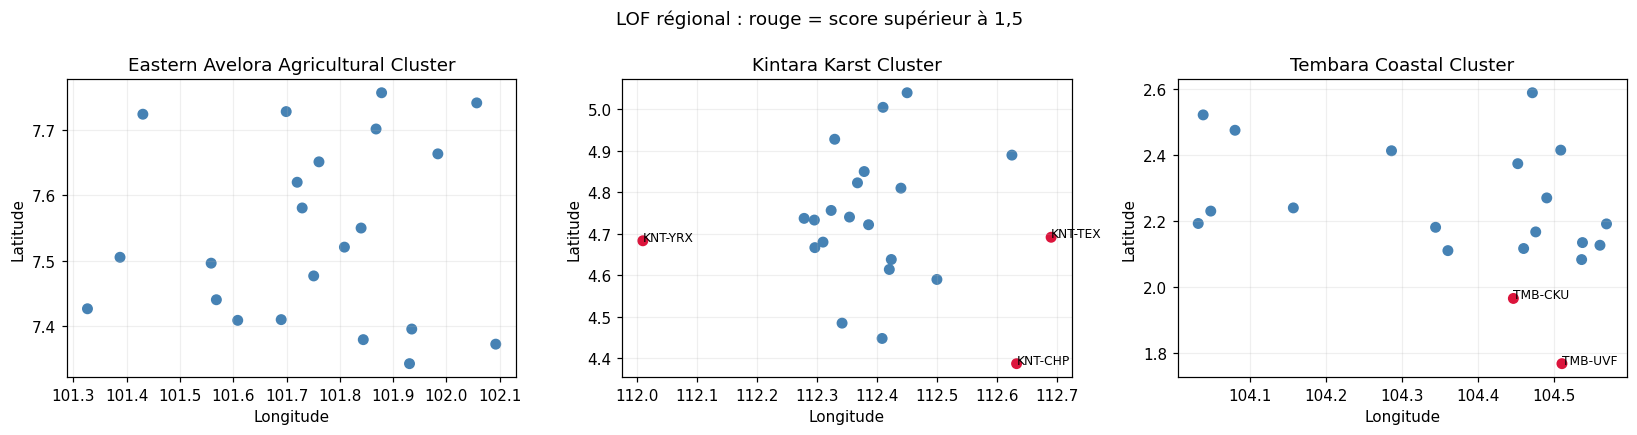

In [32]:
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax,(region,g) in zip(axes,df.groupby('region')):
    flags=g.site_code.isin(lof_main.loc[lof_main.signalee,'site_code'])
    ax.scatter(g.longitude,g.latitude,c=np.where(flags,'crimson','steelblue'),s=38)
    for _,r in g.loc[flags].iterrows():ax.annotate(r.site_code,(r.longitude,r.latitude),fontsize=8)
    ax.set(xlabel='Longitude',ylabel='Latitude',title=region)
plt.suptitle('LOF régional : rouge = score supérieur à 1,5')
plt.tight_layout();plt.show()

# 9. Anomalies détectées


In [33]:
lof_tests=pd.DataFrame({
    'observation':lof_main.site_code,'groupe':lof_main.region,
    'variable':'latitude + longitude (Haversine)','methode':'LOF_k5',
    'valeur':lof_main.score,'score':lof_main.score,'borne_basse':-np.inf,
    'borne_haute':1.5,'n_reference':lof_main.region.map(df.region.value_counts()),
    'applicable':True,'signalee':lof_main.signalee,'regle':'LOF > 1,5',
    'interpretation':'Densité géographique localement inhabituelle'})
all_tests=pd.concat([tests,lof_tests],ignore_index=True)
register=all_tests.loc[all_tests.signalee].copy()
print('Signaux :',len(register),'| Sites distincts :',register.observation.nunique())

Signaux : 20 | Sites distincts : 8


### Afficher tous les sites concernés et les méthodes


In [34]:
bilan_sites=register.groupby('observation').agg(
    nb_signaux=('methode','size'),
    methodes=('methode',lambda x:', '.join(sorted(set(x)))),
    variables=('variable',lambda x:', '.join(sorted(set(x))))).reset_index()
display(bilan_sites.sort_values(['nb_signaux','observation'],ascending=[False,True]))

,observation,nb_signaux,methodes,variables
2,KNT-CHP,4,"IQR, LOF_k5, Z-modifie","distance_voisin_km, elevation_m, latitude + longitude (Haversine)"
0,AVL-ARU,3,"IQR, Z-modifie, Z-score",distance_voisin_km
4,KNT-TEX,3,"IQR, LOF_k5, Z-modifie","distance_voisin_km, latitude + longitude (Haversine)"
5,KNT-YRX,3,"IQR, LOF_k5, Z-modifie","distance_voisin_km, latitude + longitude (Haversine)"
7,TMB-UVF,3,"IQR, LOF_k5, Z-modifie","distance_voisin_km, latitude + longitude (Haversine)"
3,KNT-QWU,2,"IQR, Z-modifie",distance_voisin_km
1,AVL-GRB,1,Z-modifie,distance_voisin_km
6,TMB-CKU,1,LOF_k5,latitude + longitude (Haversine)


### Détail des détections et de leurs seuils


In [35]:
display(register[['observation','groupe','variable','methode','valeur','score',
                  'borne_basse','borne_haute','regle']].round(3).reset_index(drop=True))

,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,regle
0,AVL-ARU,Eastern Avelora Agricultural Cluster,distance_voisin_km,IQR,24.774,24.774,-2.381,19.042,"hors bornes IQR 1,5"
1,KNT-YRX,Kintara Karst Cluster,distance_voisin_km,IQR,30.409,30.409,-6.430,18.284,"hors bornes IQR 1,5"
2,KNT-CHP,Kintara Karst Cluster,distance_voisin_km,IQR,25.767,25.767,-6.430,18.284,"hors bornes IQR 1,5"
3,KNT-QWU,Kintara Karst Cluster,distance_voisin_km,IQR,22.337,22.337,-6.430,18.284,"hors bornes IQR 1,5"
4,KNT-TEX,Kintara Karst Cluster,distance_voisin_km,IQR,23.168,23.168,-6.430,18.284,"hors bornes IQR 1,5"
5,KNT-CHP,Kintara Karst Cluster,elevation_m,IQR,418.800,418.800,-61.200,417.200,"hors bornes IQR 1,5"
6,TMB-UVF,Tembara Coastal Cluster,distance_voisin_km,IQR,23.134,23.134,-3.106,20.615,"hors bornes IQR 1,5"
7,AVL-ARU,Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-score,24.774,3.276,-5.944,23.424,|z| > 3
8,AVL-ARU,Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-modifie,24.774,7.057,-2.881,15.456,"|z_mod| > 3,5"
9,AVL-GRB,Eastern Avelora Agricultural Cluster,distance_voisin_km,Z-modifie,17.579,4.310,-2.881,15.456,"|z_mod| > 3,5"


**Interprétation :** `KNT-CHP` dépasse très légèrement une borne d’altitude ; ce signal est faible pris isolément.


# 10. Vérification avec les vergers


In [36]:
orchards=pd.read_csv(ROOT/'data/ecology/cleaned/orchard_surveys_cleaned.csv',usecols=['site_code'])
orchard_ids=set(orchards.site_code)
site_ids=set(df.site_code)
print('Sites de vergers distincts :',len(orchard_ids))
print('Sites absents du référentiel :',sorted(orchard_ids-site_ids))
assert orchard_ids<=site_ids

Sites de vergers distincts : 16
Sites absents du référentiel : []


### Confronter les sites aux catégories déclarées


In [37]:
coverage=df[['site_code','orchard_context','site_category']].copy()
coverage['releve_verger']=coverage.site_code.isin(orchard_ids)
coverage['contexte_verger']=coverage.orchard_context.eq('commercial or research orchard')
display(pd.crosstab(coverage.contexte_verger,coverage.releve_verger))
display(coverage.loc[coverage.contexte_verger.ne(coverage.releve_verger)])

releve_verger,False,True
contexte_verger,,
False,48,0
True,0,16


,site_code,orchard_context,site_category,releve_verger,contexte_verger


**Lecture :** ce contrôle vérifie la cohérence des identifiants entre deux fichiers, pas la validité réelle des coordonnées.


# 11. Isolation Forest et DBSCAN


### a. Isolation Forest par région (comparaison avec LOF)


In [38]:
if_rows=[]
for region,g in df.groupby('region'):
    coords=g[['latitude','longitude']].to_numpy()
    model=IsolationForest(n_estimators=200, contamination=.05, random_state=42)
    flags=model.fit_predict(coords)==-1
    for site,flag in zip(g.site_code,flags):
        if_rows.append({'site_code':site,'region':region,'IF_flag':bool(flag)})
if_sites=pd.DataFrame(if_rows)
display(if_sites.loc[if_sites.IF_flag])

,site_code,region,IF_flag
5,AVL-ARU,Eastern Avelora Agricultural Cluster,True
17,AVL-SEY,Eastern Avelora Agricultural Cluster,True
26,KNT-YRX,Kintara Karst Cluster,True
32,KNT-CHP,Kintara Karst Cluster,True
53,TMB-UVF,Tembara Coastal Cluster,True


**Lecture :** avec contamination = 5 %, IF impose un quota de signaux ; ce n’est pas une preuve.


### b. DBSCAN géographique


In [39]:
db_rows=[]
for region,g in df.groupby('region'):
    coords=np.radians(g[['latitude','longitude']].to_numpy())
    labels=DBSCAN(eps=25/EARTH_KM, min_samples=2,metric='haversine').fit_predict(coords)
    for site,label in zip(g.site_code,labels):
        db_rows.append({'site_code':site,'region':region,'groupe_DBSCAN':int(label)})
db_sites=pd.DataFrame(db_rows)
display(db_sites.loc[db_sites.groupe_DBSCAN.eq(-1)])

,site_code,region,groupe_DBSCAN
26,KNT-YRX,Kintara Karst Cluster,-1
32,KNT-CHP,Kintara Karst Cluster,-1


**Lecture :** DBSCAN indique les sites sans voisin suffisant à 25 km, pas des coordonnées erronées.


### c. Comparer les méthodes


In [40]:
comparaison_sites = (df[['site_code','region']]
    .merge(lof_main[['site_code','signalee']],on='site_code')
    .merge(if_sites[['site_code','IF_flag']],on='site_code')
    .merge(db_sites[['site_code','groupe_DBSCAN']],on='site_code'))
comparaison_sites['DBSCAN_bruit']=comparaison_sites.groupe_DBSCAN.eq(-1)
display(comparaison_sites.loc[
    comparaison_sites.signalee | comparaison_sites.IF_flag | comparaison_sites.DBSCAN_bruit])

,site_code,region,signalee,IF_flag,groupe_DBSCAN,DBSCAN_bruit
9,KNT-YRX,Kintara Karst Cluster,True,True,-1,True
15,KNT-CHP,Kintara Karst Cluster,True,True,-1,True
24,KNT-TEX,Kintara Karst Cluster,True,False,0,False
29,AVL-ARU,Eastern Avelora Agricultural Cluster,False,True,0,False
41,AVL-SEY,Eastern Avelora Agricultural Cluster,False,True,0,False
48,TMB-CKU,Tembara Coastal Cluster,True,False,0,False
53,TMB-UVF,Tembara Coastal Cluster,True,True,0,False


# 12. Apriori et associations


### a. Construire des paniers catégoriels


In [41]:
paniers_sites=[{
    'type='+str(r.site_category),
    'habitat='+str(r.habitat_category),
    'verger='+str(r.orchard_context),
    'acces='+str(r.cave_access_category)}
    for r in df.itertuples()]
print('Nombre de paniers :',len(paniers_sites))

Nombre de paniers : 64


### b. Rechercher les ensembles fréquents


In [42]:
def apriori_itemsets(transactions, min_support=.08, max_size=3):
    """Apriori : construire et élaguer des ensembles fréquents de taille 1 à 3."""
    paniers=[set(t) for t in transactions]
    n=len(paniers)
    counts=Counter(item for panier in paniers for item in panier)
    freq={frozenset([x]):v/n for x,v in counts.items() if v/n>=min_support}
    all_freq=dict(freq)
    for k in range(2,max_size+1):
        uniques=sorted(set().union(*[set(f) for f in freq])) if freq else []
        candidates=(frozenset(combo) for combo in combinations(uniques,k))
        candidates=[c for c in candidates if all(frozenset(s) in freq
                        for s in combinations(c,k-1))]
        freq={c:sum(c<=panier for panier in paniers)/n for c in candidates}
        freq={c:s for c,s in freq.items() if s>=min_support}
        all_freq.update(freq)
    return all_freq

In [43]:
freq_sites=apriori_itemsets(paniers_sites, min_support=0.08, max_size=3)
print('Ensembles fréquents :',len(freq_sites))

Ensembles fréquents : 49


### c. Règles : support, confiance, lift


In [44]:
def regles_apriori(freq, min_confiance=.6, min_lift=1.1):
    """Extraire support, confiance et lift pour toutes les règles fréquentes."""
    lignes=[]
    for ensemble,support in freq.items():
        if len(ensemble)<2:continue
        for taille in range(1,len(ensemble)):
            for part in combinations(sorted(ensemble),taille):
                gauche=frozenset(part);droite=ensemble-gauche
                confiance=support/freq[gauche]
                lift=confiance/freq[droite]
                if confiance>=min_confiance and lift>=min_lift:
                    lignes.append({'antecedent':' + '.join(sorted(gauche)),
                        'consequent':' + '.join(sorted(droite)),
                        'support':support,'confiance':confiance,'lift':lift})
    return pd.DataFrame(lignes,columns=['antecedent','consequent',
                                        'support','confiance','lift'])

In [45]:
regles_sites=regles_apriori(freq_sites)
print('Règles retenues :',len(regles_sites))
display(regles_sites.sort_values('lift',ascending=False).head(12).round(3))

Règles retenues : 93


,antecedent,consequent,support,confiance,lift
43,type=cave monitoring + verger=none recorded,acces=managed,0.125,1.000,8.000
33,habitat=karst_habitat + type=cave monitoring,acces=managed,0.109,1.000,8.000
30,type=cave monitoring,acces=managed + habitat=karst_habitat,0.109,0.875,8.000
39,acces=managed,type=cave monitoring + verger=none recorded,0.125,1.000,8.000
40,type=cave monitoring,acces=managed + verger=none recorded,0.125,1.000,8.000
42,acces=managed + verger=none recorded,type=cave monitoring,0.125,1.000,8.000
31,acces=managed + habitat=karst_habitat,type=cave monitoring,0.109,1.000,8.000
28,acces=managed,habitat=karst_habitat + type=cave monitoring,0.109,0.875,8.000
3,type=cave monitoring,acces=managed,0.125,1.000,8.000
2,acces=managed,type=cave monitoring,0.125,1.000,8.000


→ Résultat exploratoire : une association fréquente ne prouve pas une cause.


### d. Croiser les alertes avec les incohérences


In [46]:
controle_sites=df[['site_code','region','coord_valides','coord_dupliquees']].copy()
controle_sites['altitude_absente']=df.elevation_m.isna()
controle_sites=controle_sites.merge(comparaison_sites.drop(columns='region'),on='site_code')
controle_sites['IQR_Z']=controle_sites.site_code.isin(stat_ids)
controle_sites['anomalie_qualitative']=(~controle_sites.coord_valides |
    controle_sites.coord_dupliquees | controle_sites.altitude_absente)
display(pd.crosstab(controle_sites.IQR_Z,controle_sites.anomalie_qualitative))
display(controle_sites.loc[controle_sites.anomalie_qualitative | controle_sites.IQR_Z |
    controle_sites.signalee | controle_sites.IF_flag | controle_sites.DBSCAN_bruit])

anomalie_qualitative,False,True
IQR_Z,,
False,56,1
True,7,0


,site_code,region,coord_valides,coord_dupliquees,altitude_absente,signalee,IF_flag,groupe_DBSCAN,DBSCAN_bruit,IQR_Z,anomalie_qualitative
8,KNT-CYP,Kintara Karst Cluster,True,False,True,False,False,0,False,False,True
9,KNT-YRX,Kintara Karst Cluster,True,False,False,True,True,-1,True,True,False
15,KNT-CHP,Kintara Karst Cluster,True,False,False,True,True,-1,True,True,False
20,KNT-QWU,Kintara Karst Cluster,True,False,False,False,False,0,False,True,False
24,KNT-TEX,Kintara Karst Cluster,True,False,False,True,False,0,False,True,False
29,AVL-ARU,Eastern Avelora Agricultural Cluster,True,False,False,False,True,0,False,True,False
30,AVL-GRB,Eastern Avelora Agricultural Cluster,True,False,False,False,False,0,False,True,False
41,AVL-SEY,Eastern Avelora Agricultural Cluster,True,False,False,False,True,0,False,False,False
48,TMB-CKU,Tembara Coastal Cluster,True,False,False,True,False,0,False,False,False
53,TMB-UVF,Tembara Coastal Cluster,True,False,False,True,True,0,False,True,False


→ L’altitude absente est un problème de complétude, pas un site spatialement faux.


# 13. Graphe des sites


In [47]:
network_rows=[]; degrees_25=[]
for region,g in valid.groupby('region'):
    coords=np.radians(g[['latitude','longitude']].to_numpy())
    d=haversine_distances(coords)*EARTH_KM
    for rayon in [15,25,35]:
        adj=(d<=rayon)&(~np.eye(len(g),dtype=bool))
        components,labels=connected_components(csr_matrix(adj.astype(int)),directed=False)
        degrees=adj.sum(axis=1)
        network_rows.append(dict(region=region,seuil_km=rayon,n_sites=len(g),
            n_aretes=int(adj.sum()/2),composantes=int(components),
            isolés=int((degrees==0).sum())))
        if rayon==25:
            degrees_25 += [dict(site_code=site,region=region,degre_25km=int(degree))
                           for site,degree in zip(g.site_code,degrees)]
network_summary=pd.DataFrame(network_rows)
degrees_sites=pd.DataFrame(degrees_25)

### Lire les composantes et sites isolés


In [48]:
display(network_summary.sort_values(['region','seuil_km']))
display(degrees_sites.loc[degrees_sites.degre_25km.eq(0)])
assert len(degrees_sites)==len(valid)

,region,seuil_km,n_sites,n_aretes,composantes,isolés
0,Eastern Avelora Agricultural Cluster,15,22,28,4,2
1,Eastern Avelora Agricultural Cluster,25,22,72,1,0
2,Eastern Avelora Agricultural Cluster,35,22,125,1,0
3,Kintara Karst Cluster,15,22,50,6,4
4,Kintara Karst Cluster,25,22,98,3,2
5,Kintara Karst Cluster,35,22,147,1,0
6,Tembara Coastal Cluster,15,20,28,7,4
7,Tembara Coastal Cluster,25,20,59,1,0
8,Tembara Coastal Cluster,35,20,89,1,0


,site_code,region,degre_25km
26,KNT-YRX,Kintara Karst Cluster,0
32,KNT-CHP,Kintara Karst Cluster,0


### Visualiser la sensibilité au seuil


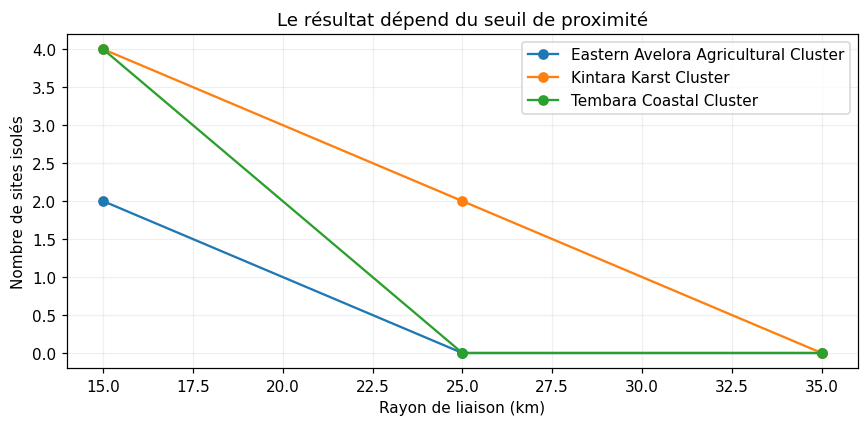

In [49]:
fig,ax=plt.subplots(figsize=(8,4))
for region,g in network_summary.groupby('region'):
    ax.plot(g.seuil_km,g['isolés'],marker='o',label=region)
ax.set(xlabel='Rayon de liaison (km)',ylabel='Nombre de sites isolés',
       title='Le résultat dépend du seuil de proximité')
ax.legend();plt.tight_layout();plt.show()

# 14. Conclusion


### Ce qu’on a trouvé

On a étudié **64 sites** répartis dans trois régions. Les coordonnées sont valides et on ne trouve pas de doublons. Il manque seulement une altitude, ainsi que les dates de fin des programmes.

Avec **IQR, Z-score et LOF**, on a repéré **8 sites différents** qui sortent un peu du lot (20 signaux au total, car un même site peut être détecté plusieurs fois). Par exemple, `KNT-YRX` et `KNT-CHP` sont assez isolés par rapport aux autres sites de leur région.

Pour le **clustering**, K-Means a retenu **5 groupes**. La CAH donne des groupes assez proches (**ARI = 0,668**). On a aussi testé Isolation Forest et DBSCAN pour comparer les résultats.


### Ce qu’on en conclut

Ces résultats montrent surtout que certains sites ont des caractéristiques moins courantes. **Cela ne veut pas dire que leurs coordonnées sont fausses** : ils peuvent simplement avoir été placés dans des zones plus éloignées pour le suivi écologique.

Pour aller plus loin, il faudrait regarder les relevés des vergers et les autres données écologiques de ces sites. **On garde donc ces observations comme des pistes à vérifier, sans supprimer ni corriger de données.**
